In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV
import shap

In [ ]:
train=pd.read_csv('./train_dataset.txt',sep='\t')
test=pd.read_csv('./test_dataset.txt',sep='\t')

In [9]:
x_train = np.array(train.iloc[:,1:-7])
y_train = (np.array(train.iloc[:,-7]))
x_test = np.array(test.iloc[:,1:-7])
y_test = (np.array(test.iloc[:,-7]))

In [23]:
param_dist = {
    'learning_rate': [0.03],
    'n_estimators': [500],
    'max_depth': np.arange(1,11,step=1),
    'min_samples_split': np.arange(20,51,step=1),
    'min_samples_leaf': np.arange(1,21,step=1),
    'max_features': np.arange(1,16,step=1)
}
model = GradientBoostingRegressor(random_state=42)
random_search = RandomizedSearchCV(
    model, param_distributions=param_dist, n_iter=200, cv=5, n_jobs=20, scoring='neg_root_mean_squared_error',random_state=42
)
random_search.fit(x_train, y_train)
print("Best Parameters:", random_search.best_params_)
model = random_search.best_estimator_

Best Parameters: {'n_estimators': 500, 'min_samples_split': 48, 'min_samples_leaf': 11, 'max_features': 14, 'max_depth': 9, 'learning_rate': 0.03}


In [10]:
from sklearn.ensemble import GradientBoostingRegressor
model = GradientBoostingRegressor(random_state=42,n_estimators= 500, min_samples_split= 48, min_samples_leaf= 11, max_features= 14, max_depth= 9, learning_rate= 0.03)
model.fit(x_train, y_train)

GradientBoostingRegressor(learning_rate=0.03, max_depth=9, max_features=14,
                          min_samples_leaf=11, min_samples_split=48,
                          n_estimators=500, random_state=42)

In [35]:
y_train_predict=model.predict(x_train)
train_scatter=pd.DataFrame(columns=['Transcript_ID','True decay rate','Predicted decay rate'])
train_scatter['Transcript_ID']=train['isoform']
train_scatter['True decay rate']=y_train
train_scatter['Predicted decay rate']=y_train_predict
train_scatter.reset_index(drop=True,inplace=True)
train_scatter.to_csv('/disk1/work/chenlong/ONT/decay_project_20250401-version/ml/data/train_scatter.txt',sep='\t',index=False)

In [18]:
y_test_predict=model.predict(x_test)
test_scatter=pd.DataFrame(columns=['Transcript_ID','True decay rate','Predicted decay rate'])
test_scatter['Transcript_ID']=test['isoform']
test_scatter['True decay rate']=y_test
test_scatter['Predicted decay rate']=y_test_predict
test_scatter.reset_index(drop=True,inplace=True)
test_scatter.to_csv('/disk1/work/chenlong/ONT/decay_project_20250401-version/ml/data/test_scatter.txt',sep='\t',index=False)

Text(0.5, 0, 'Feature importance based on mean decrease in impurity')

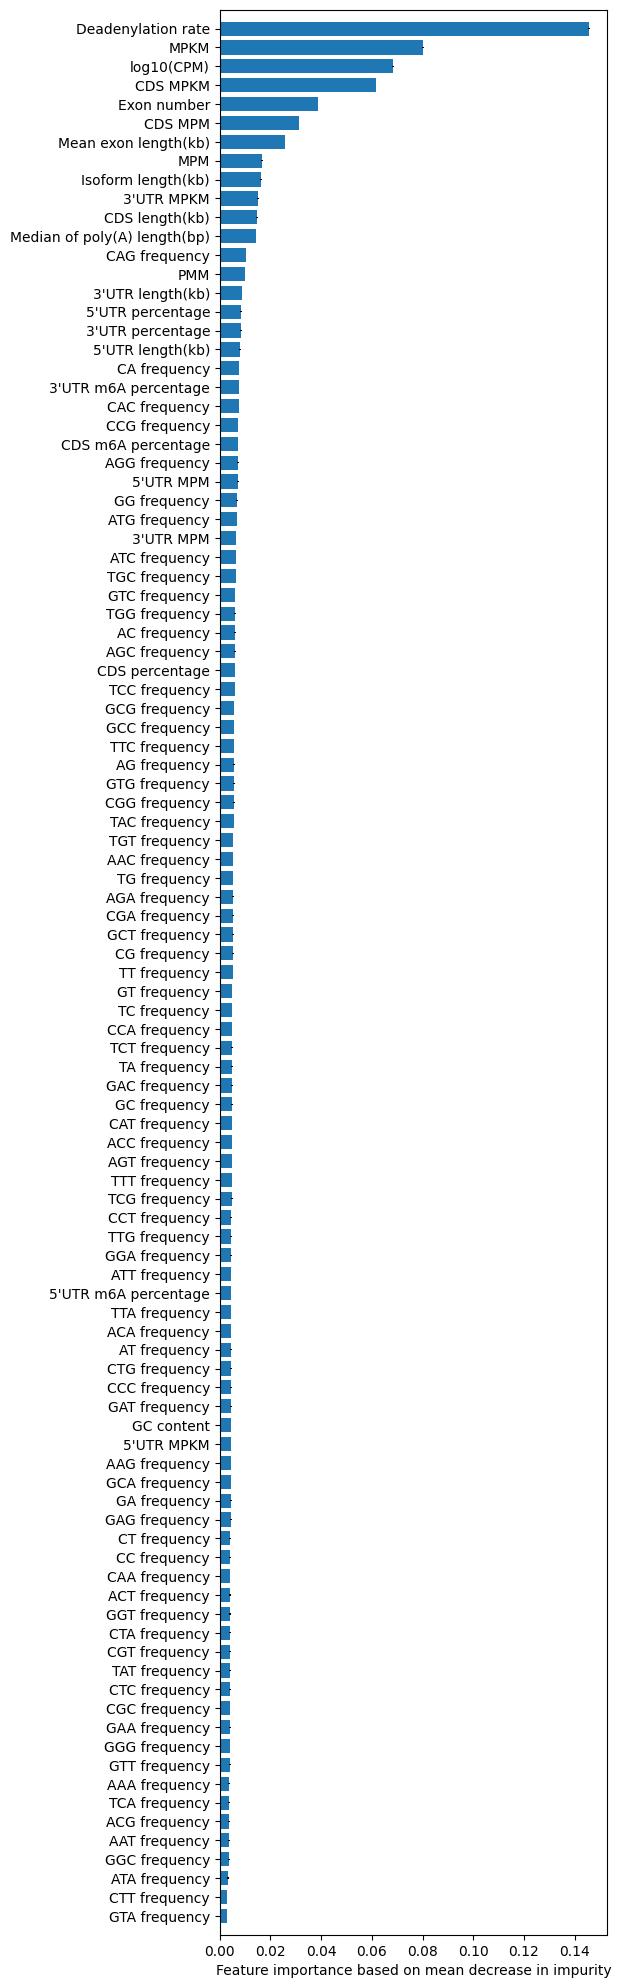

In [46]:
plt.figure(figsize=(5,25))
sorted_indices = np.argsort(model.feature_importances_)
std = np.std([tree[0].feature_importances_ for tree in model.estimators_], axis=0)
plt.barh(train.columns[1:-7][sorted_indices],model.feature_importances_[sorted_indices],height=0.75,yerr=std)
plt.ylim(bottom=-1,top=101)
plt.yticks(fontsize=10)
plt.xlabel('Feature importance based on mean decrease in impurity')

In [ ]:
def validate_plot(model,x,y):
    from scipy.stats import pearsonr
    from scipy.stats import gaussian_kde
    from sklearn.metrics import r2_score
    y_pred = model.predict(x)
    corr, p_value = pearsonr(y_pred, y)
    r2 = r2_score(y, y_pred)
    xy = np.vstack([y, y_pred])
    density = gaussian_kde(xy)(xy)
    plt.figure(figsize=(4,3))
    scatter=  plt.scatter(y,y_pred,s=10, c=density, cmap='coolwarm')
    plt.xlabel('True decay rate')
    plt.ylabel('Predicted decay rate')
    plt.xlim(-0.24,0.74)
    plt.ylim(-0.24,0.74)
    plt.yticks(np.arange(-0.2,0.71,step=0.1))
    plt.xticks(np.arange(-0.2,0.71,step=0.1))
    plt.text(s=f'Pearson\'s r: {round(corr,3)}',y=0.55,x=-0.2)
    plt.plot([-0.2,1.2],[-0.2,1.2],c='red',ls='--',label='y = x')
    cbar=plt.colorbar(scatter,label='KDE density')
    plt.legend(frameon=False)

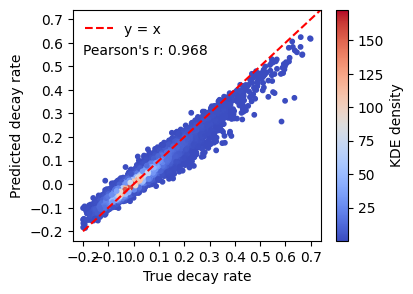

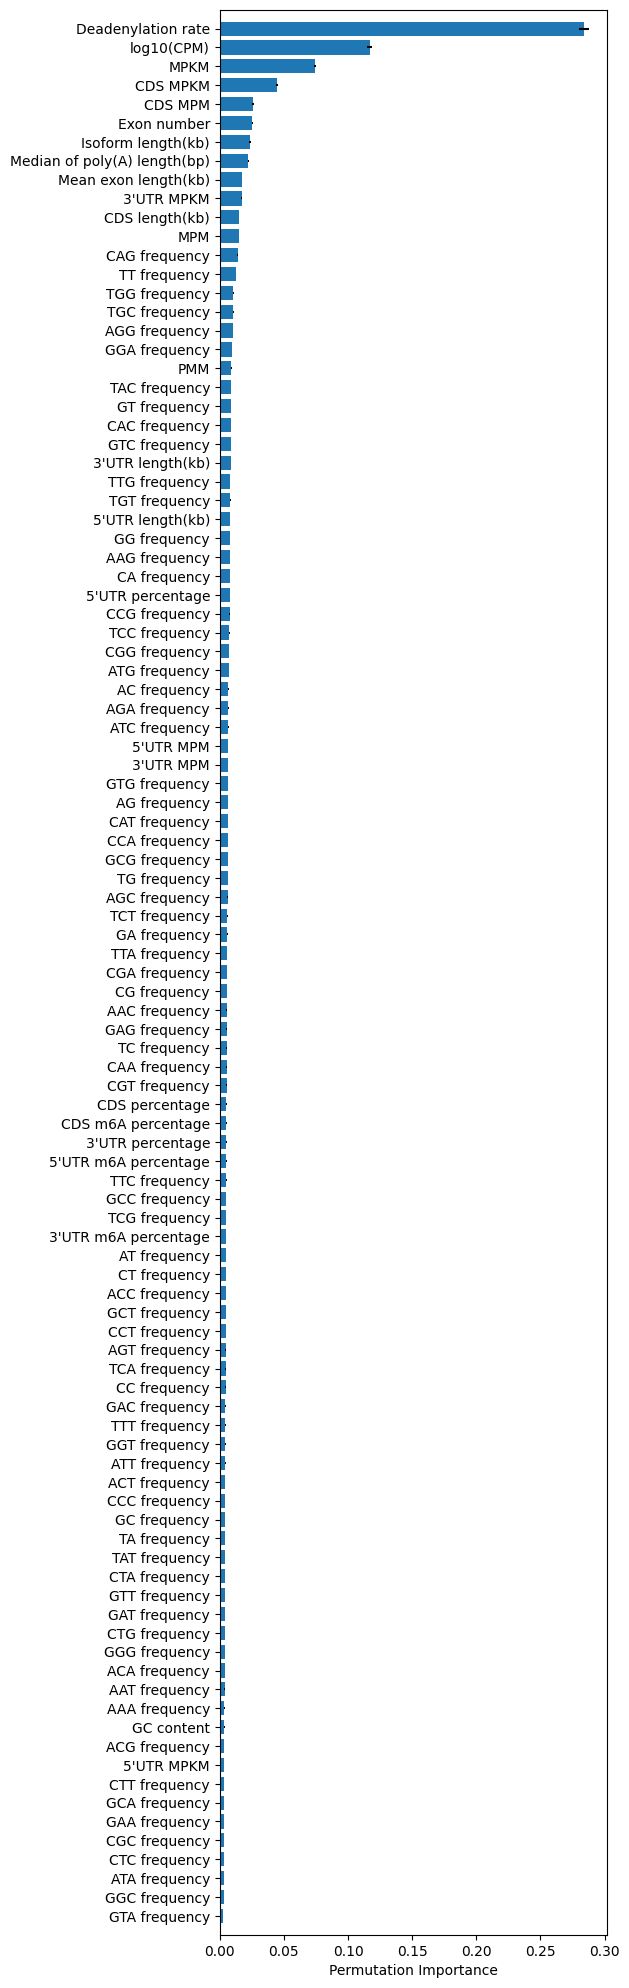

In [49]:
validate_plot(model,x_train,y_train)
from sklearn.inspection import permutation_importance
result = permutation_importance(
    model, x_train, y_train, n_repeats= 10, random_state=42, n_jobs=10
)
plt.figure(figsize=(5,25))
sorted_indices = np.argsort(result.importances_mean)
plt.barh(train.columns[1:-2][sorted_indices],result.importances_mean[sorted_indices],xerr=result.importances_std[sorted_indices],height=0.75)
plt.ylim(bottom=-1,top=101)
plt.yticks(fontsize=10)
plt.xlabel('Permutation Importance')

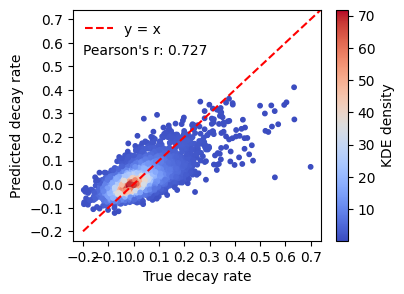

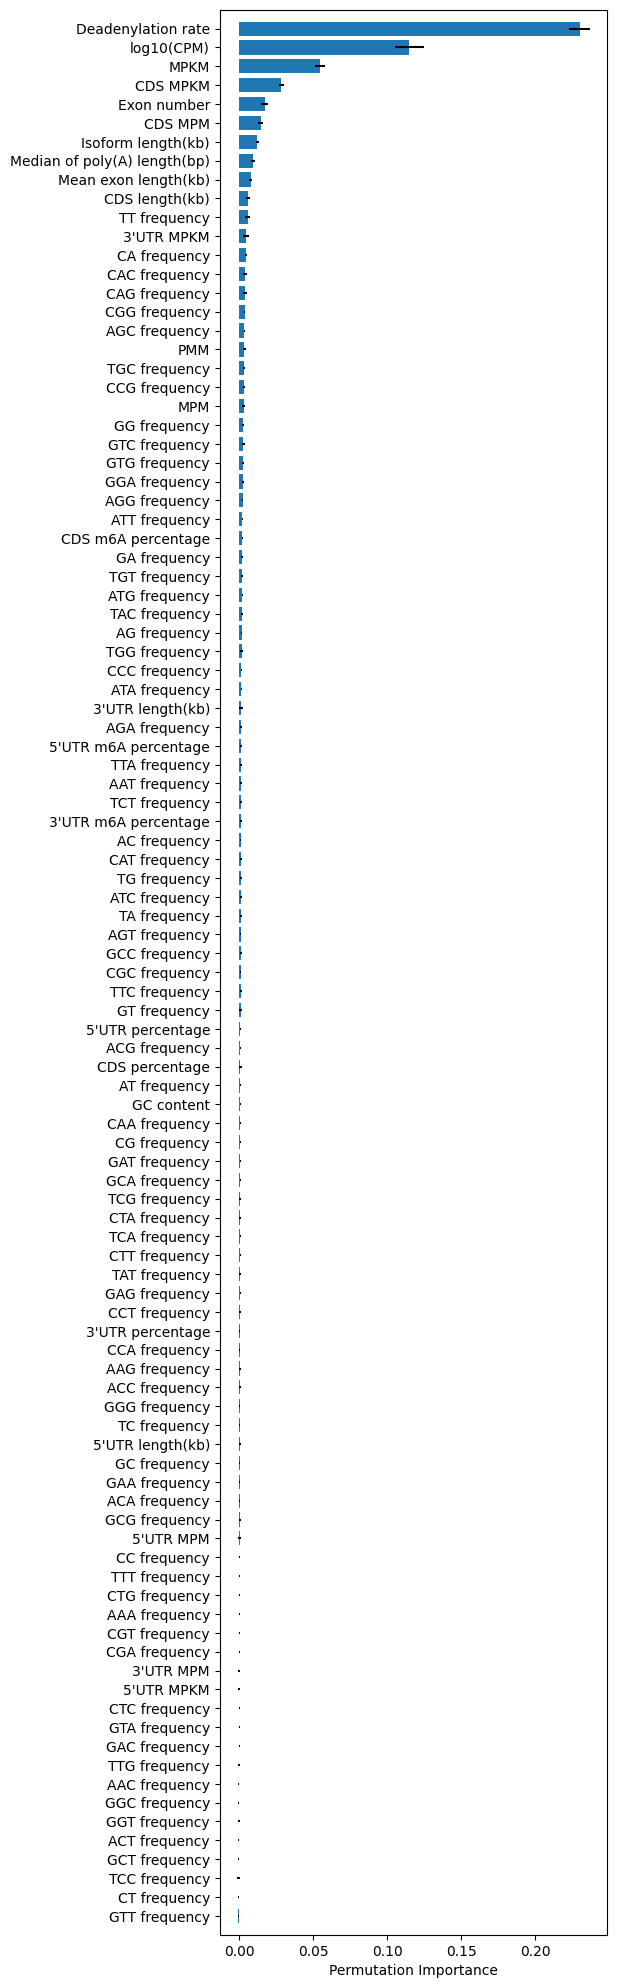

In [13]:
validate_plot(model,x_test,y_test)
from sklearn.inspection import permutation_importance
result = permutation_importance(
    model, x_test, y_test, n_repeats= 10, random_state=42, n_jobs=10
)
plt.figure(figsize=(5,25))
sorted_indices = np.argsort(result.importances_mean)
plt.barh(valid.columns[1:-2][sorted_indices],result.importances_mean[sorted_indices],xerr=result.importances_std[sorted_indices],height=0.75)
plt.ylim(bottom=-1,top=101)
plt.yticks(fontsize=10)
plt.xlabel('Permutation Importance')


In [ ]:
concat_df=pd.concat([train,test])

In [54]:
features = concat_df.set_index('isoform').iloc[:,:-1]
explainer = shap.TreeExplainer(model)
shap_explainer = explainer(features)
shap_values = explainer.shap_values(features)

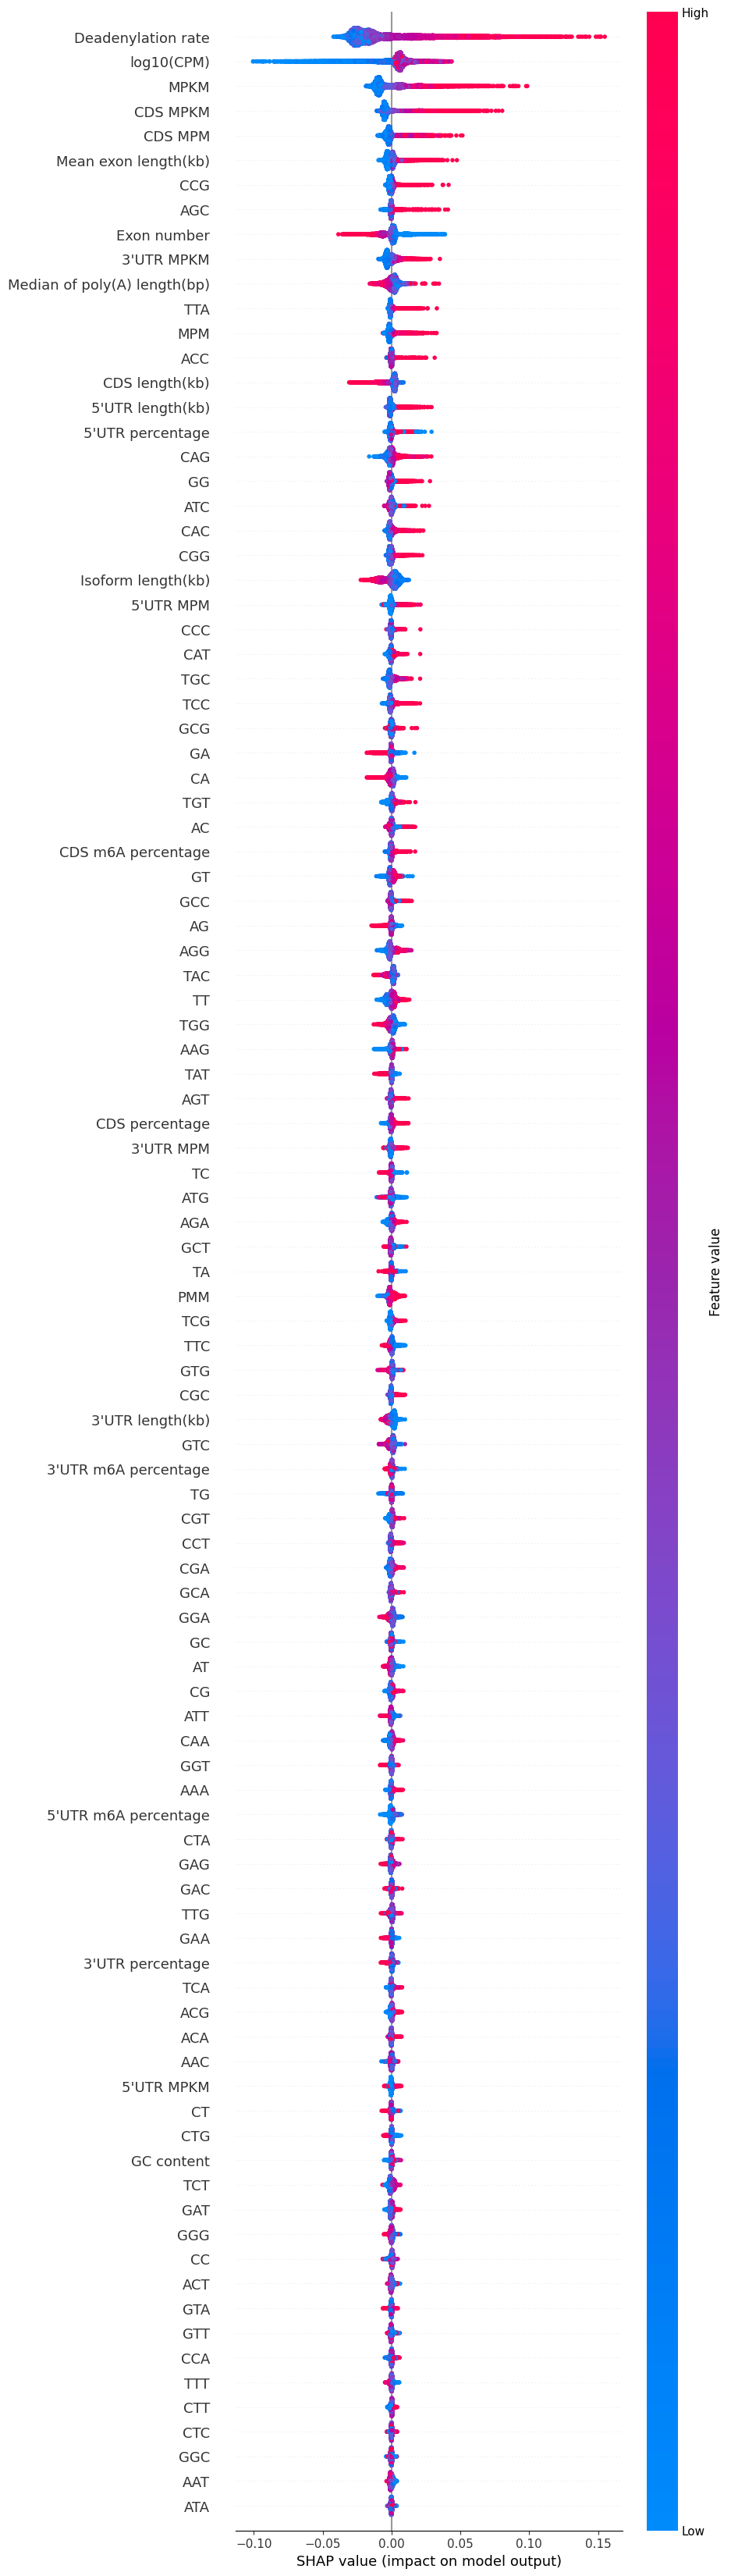

In [30]:
shap.plots.beeswarm(shap_explainer, order=shap_explainer.abs.max(0), max_display=101)